# 02 · Tipos de dados no Modbus, escala e quadro RTU

**Objetivo:** entender por que o mesmo par de registradores pode virar 123,456 ou -1,88e+25 dependendo de como você lê, e como é um quadro Modbus de verdade, byte a byte.

Este notebook não precisa de servidor: são funções puras, então dá para rodar em qualquer lugar.

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from common.notebook import load, run_in_background, require_broker
d = load("02-modbus-data-types-rtu/datatypes.py")

## 1. Float de 32 bits em dois registradores

O Modbus só transporta palavras de 16 bits. Um `float` IEEE-754 ocupa 32 bits, então vai dividido em **dois registradores**. A norma não diz qual metade vai primeiro, e cada fabricante escolhe:

* **big (ABCD)**: palavra alta primeiro (Schneider, a maioria)
* **little / word swap (CDAB)**: palavra baixa primeiro (muitos medidores de energia)

In [2]:
valor = 123.456
for ordem in ("big", "little"):
    regs = d.float32_to_regs(valor, ordem)
    print(f"{ordem:6} -> registradores {[hex(r) for r in regs]}  -> lido de volta: {d.regs_to_float32(regs, ordem):.3f}")

errado = d.regs_to_float32(d.float32_to_regs(valor, "big"), "little")
print(f"\nGravado em big, lido como little: {errado:.6g}")

big    -> registradores ['0x42f6', '0xe979']  -> lido de volta: 123.456
little -> registradores ['0xe979', '0x42f6']  -> lido de volta: 123.456

Gravado em big, lido como little: -1.88337e+25


**Interpretação:** os dois bytes de cada palavra estão certos, mas as palavras trocaram de lugar. O resultado é um número absurdo (-1,88 × 10²⁵). Quando um valor no SCADA aparece "aleatório" e gigante, a primeira suspeita é a **ordem das palavras**.

## 2. Inteiros de 32 bits e negativos

In [3]:
print("contador 32 bits [0x0001, 0x86A0] ->", d.regs_to_uint32([0x0001, 0x86A0]))
print("  conta: 0x0001 * 65536 + 0x86A0 =", 1 * 65536 + 0x86A0)
print()
for raw in (0x000A, 0x7FFF, 0x8000, 0xFFF6):
    print(f"registrador 0x{raw:04X} = {raw:5d} sem sinal  ->  {d.regs_to_int16(raw):6d} com sinal")

contador 32 bits [0x0001, 0x86A0] -> 100000
  conta: 0x0001 * 65536 + 0x86A0 = 100000

registrador 0x000A =    10 sem sinal  ->      10 com sinal
registrador 0x7FFF = 32767 sem sinal  ->   32767 com sinal
registrador 0x8000 = 32768 sem sinal  ->  -32768 com sinal
registrador 0xFFF6 = 65526 sem sinal  ->     -10 com sinal


**Interpretação:** o registrador sempre chega sem sinal (0 a 65535). Valores com o bit mais alto ligado (≥ 0x8000) representam **negativos em complemento de dois**. `0xFFF6` = -10, que numa escala x10 seria uma temperatura de **-1,0 °C**. Ler como sem sinal mostraria 6553,4 °C.

## 3. Escala de sinais analógicos

Um CLP converte o sinal do sensor em contagens. A Siemens usa 0 a 27648 para o fundo de escala; a conversão para engenharia é uma reta.

13824 contagens em 0..27648 para 0..10 bar -> 5.0 bar

4-20 mA num transmissor de 0 a 150 °C, com limites NAMUR NE43:
    2.1 mA -> ---   LOW SIGNAL FAULT (wire break?)
    3.9 mA ->    0.0 °C   OK
    4.0 mA ->    0.0 °C   OK
   12.0 mA ->   75.0 °C   OK
   20.0 mA ->  150.0 °C   OK
   20.4 mA ->  150.0 °C   OK
   21.5 mA -> ---   HIGH SIGNAL FAULT (short circuit?)


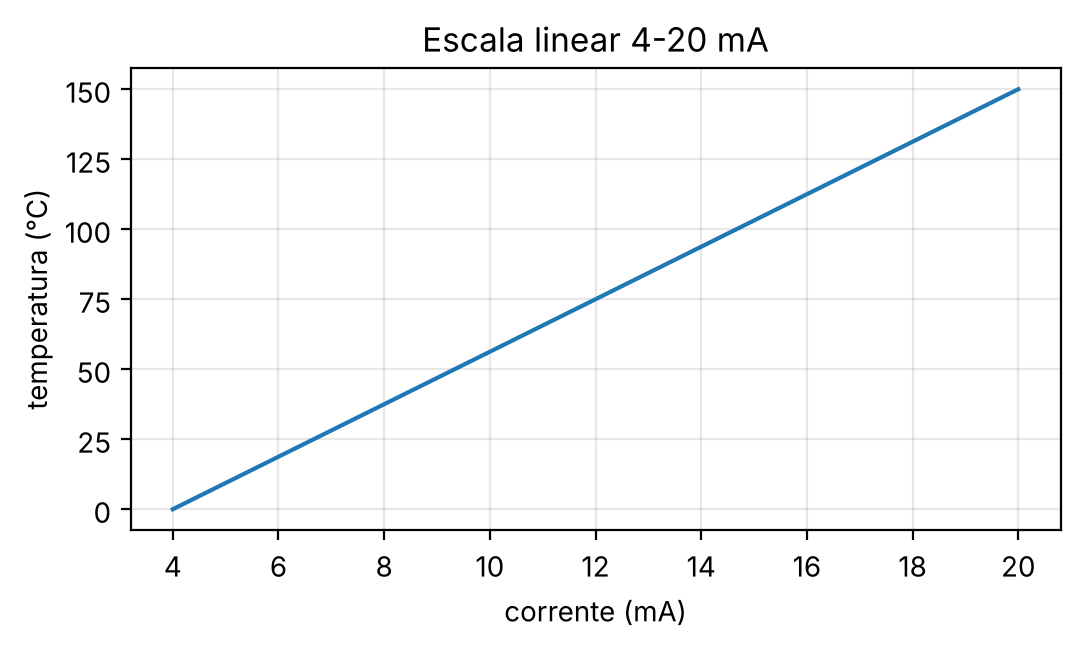

In [4]:
import numpy as np, matplotlib.pyplot as plt
print("13824 contagens em 0..27648 para 0..10 bar ->", d.scale(13824, 0, 27648, 0, 10), "bar")

print("\n4-20 mA num transmissor de 0 a 150 °C, com limites NAMUR NE43:")
for ma in (2.1, 3.9, 4.0, 12.0, 20.0, 20.4, 21.5):
    v, estado = d.ma_to_eu(ma, 0, 150)
    print(f"  {ma:5.1f} mA -> {'---' if v is None else f'{v:6.1f} °C'}   {estado}")

ma = np.linspace(4, 20, 50)
plt.figure(figsize=(6, 3)); plt.plot(ma, [d.ma_to_eu(x, 0, 150)[0] for x in ma])
plt.xlabel("corrente (mA)"); plt.ylabel("temperatura (°C)"); plt.title("Escala linear 4-20 mA"); plt.grid(alpha=.3); plt.show()

**Por que 4 mA e não 0?** O "zero vivo" deixa distinguir **0 °C** (4 mA) de **fio rompido** (0 mA). A NAMUR NE43 define: abaixo de 3,8 mA ou acima de 20,5 mA é falha do sinal, não medição. Repare que 2,1 mA e 21,5 mA viram falha, e não uma temperatura negativa ou acima do fundo de escala.

## 4. Palavra de status com bits

In [5]:
palavra = 0b100011
print(f"palavra = {palavra} = 0b{palavra:06b}")
for nome, ligado in d.unpack_status(palavra).items():
    print(f"  bit {d.STATUS_BITS.index(nome)}  {nome:<11} {ligado}")

palavra = 35 = 0b100011
  bit 0  ready       True
  bit 1  running     True
  bit 2  fault       False
  bit 3  local_mode  False
  bit 4  door_open   False
  bit 5  estop_ok    True


Um único registrador carrega até 16 flags. Aqui os bits 0, 1 e 5 estão ligados: **pronto**, **rodando** e **emergência OK**. Equipamentos fazem isso para economizar leituras.

## 5. O quadro na rede: RTU e TCP

A **mesma pergunta** ("leia 2 holding registers a partir do 100 no escravo 1") vai diferente em serial (RTU) e em Ethernet (TCP).

In [6]:
rtu = d.rtu_read_holding(unit=1, address=100, count=2)
tcp = d.tcp_read_holding(transaction=1, unit=1, address=100, count=2)

print("RTU:", rtu.hex(" "))
print("     [01]=escravo [03]=FC [00 64]=endereço 100 [00 02]=quantidade [85 d4]=CRC (byte baixo primeiro)")
print("     CRC confere:", d.rtu_check(rtu))
print()
print("TCP:", tcp.hex(" "))
print("     [00 01]=transação [00 00]=protocolo [00 06]=bytes seguintes [01]=unidade [03 00 64 00 02]=mesma PDU")
print()
corrompido = rtu[:-1] + bytes([rtu[-1] ^ 0x01])
print("RTU com 1 bit trocado na linha:", corrompido.hex(" "), " CRC confere:", d.rtu_check(corrompido))

RTU: 01 03 00 64 00 02 85 d4
     [01]=escravo [03]=FC [00 64]=endereço 100 [00 02]=quantidade [85 d4]=CRC (byte baixo primeiro)
     CRC confere: True

TCP: 00 01 00 00 00 06 01 03 00 64 00 02
     [00 01]=transação [00 00]=protocolo [00 06]=bytes seguintes [01]=unidade [03 00 64 00 02]=mesma PDU

RTU com 1 bit trocado na linha: 01 03 00 64 00 02 85 d5  CRC confere: False


**Interpretação**

* A parte do meio (`03 00 64 00 02`, a **PDU**) é idêntica nos dois. Muda só o envelope.
* No **RTU** o envelope é o endereço do escravo no começo e um **CRC-16** no fim. Basta um bit trocado por ruído na linha RS-485 e o CRC deixa de bater: o escravo descarta o quadro.
* No **TCP** não há CRC (o TCP já garante integridade). No lugar vem o cabeçalho **MBAP**, com número de transação para casar pergunta e resposta.

`01 03 00 64 00 02 85 D4` é o quadro de exemplo que aparece em quase todo material de Modbus. Se o seu CRC bater com esse, sua implementação está certa.

## Resumo

* Tudo no Modbus é registrador de 16 bits. **Float, int32, sinal e escala são convenção**, e um erro de convenção gera números plausíveis e errados.
* Confira sempre: ordem das palavras, sinal, escala, unidade.
* 4-20 mA tem diagnóstico embutido: fora de 3,8 a 20,5 mA é falha.
* RTU = PDU + endereço + CRC; TCP = MBAP + PDU.